# Gradient Boosting Model
How effectively can Gradient Boosting predict the average attainment 8 score of a school, and how does its predictive accuracy compare with the group's Linear Regression and Random Forest models? 
Gradient Boosting builds a model by adding trees sequentially, with each new tree trying to correct errors made by the previous ones[1]. 
We extracted some columns from the original dataset to create a training/test split. All model selection and 5-fold cross-validation happen only on training data. We evaluate the final chosen model once on the test data. The main comparison metric is RMSE; AIC is examined critically as an additional complexity-sensitive measure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold, GroupKFold, GridSearchCV, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
train_data = pd.read_csv('attainment8_train.csv')
test_data = pd.read_csv('attainment8_test.csv')
print('Training shape:', train_data.shape)
print('Test shape:', test_data.shape)
print('Years in training:', sorted(train_data.time_period.unique()))
print('Years in test:', sorted(test_data.time_period.unique()))

Training shape: (7873, 78)
Test shape: (1969, 78)
Years in training: [np.int64(202324), np.int64(202425), np.int64(202526)]
Years in test: [np.int64(202324), np.int64(202425), np.int64(202526)]


Attainment 8 is built from English, maths, EBacc and open scores, so we can't use those as predictors: that would practically give the model the answer. We also leave out GCSE results, Progress 8, exam-entry figures and subgroup Attainment 8 scores. Instead, we use a smaller set of school and pupil characteristics.

A limitation: these demographic fields are recorded alongside the outcome in this dataset. They are not necessarily known before the GCSE results. So this is best described as a school-context prediction exercise, rather than a proven real-world forecast. To claim a genuinely prospective forecast, we'd need earlier-year predictor data.

We also exclude school IDs, names, local authority IDs and year from the predictors. We keep school IDs and local authorities separately to test generalisation later.

In [2]:
target = 'attainment8_average'
numeric_features = [
    'allks_pupil_count', 'min_age', 'max_age',
    'sen_pupil_percent', 'sen_with_ehcp_pupil_percent',
    'ks4_disadvantaged_pupil_percent',
    'ks4_first_language_other_than_english_pupil_percent',
]
categorical_features = [
    'establishment_type_group', 'school_admission_type', 'sex_policy'
]
features = numeric_features + categorical_features
assert set(features + [target, 'school_urn', 'new_la_code']).issubset(train_data.columns)
X_train = train_data[features].copy()
y_train = train_data[target].copy()
X_test = test_data[features].copy()
y_test = test_data[target].copy()
print('Selected predictors:', features)
print('Missing values in training predictors:')
print(X_train.isna().sum().to_string())
print('Missing outcomes:', y_train.isna().sum(), y_test.isna().sum())
assert y_train.notna().all() and y_test.notna().all()

Selected predictors: ['allks_pupil_count', 'min_age', 'max_age', 'sen_pupil_percent', 'sen_with_ehcp_pupil_percent', 'ks4_disadvantaged_pupil_percent', 'ks4_first_language_other_than_english_pupil_percent', 'establishment_type_group', 'school_admission_type', 'sex_policy']
Missing values in training predictors:
allks_pupil_count                                      0
min_age                                                0
max_age                                                0
sen_pupil_percent                                      0
sen_with_ehcp_pupil_percent                            0
ks4_disadvantaged_pupil_percent                        0
ks4_first_language_other_than_english_pupil_percent    0
establishment_type_group                               0
school_admission_type                                  0
sex_policy                                             0
Missing outcomes: 0 0


We use a pipeline so that missing-value handling and one-hot encoding are fitted inside each training fold. This avoids letting information from the validation folds influence preprocessing.

In [3]:
preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric_features),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

def make_model(**kwargs):
    settings = dict(random_state=RANDOM_STATE, n_estimators=100,
                    learning_rate=0.1, max_depth=3, subsample=1.0)
    settings.update(kwargs)
    return Pipeline([
        ('preprocess', preprocessor),
        ('model', GradientBoostingRegressor(**settings))
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_cv(estimator, X, y, splitter=cv, groups=None):
    scores = cross_validate(estimator, X, y, cv=splitter, groups=groups,
                            scoring='neg_root_mean_squared_error',
                            return_train_score=True, n_jobs=-1)
    return (-scores['test_score'], -scores['train_score'])

Before fitting anything, we check the distribution of Attainment 8. Unusually high or low scores could be harder to predict, which we'll revisit in the residual analysis.

count    7873.00
mean       46.92
std         9.42
min         0.80
25%        40.90
50%        45.80
75%        51.10
max        87.30
Name: attainment8_average, dtype: float64


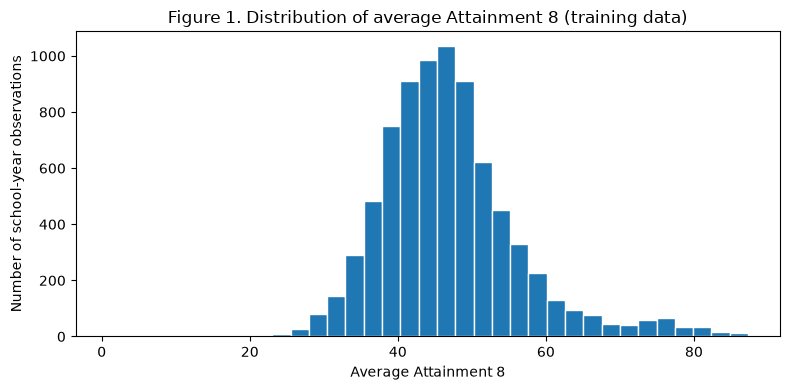

In [4]:
print(y_train.describe().round(2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train, bins=35, edgecolor='white')
ax.set(title='Figure 1. Distribution of average Attainment 8 (training data)',
       xlabel='Average Attainment 8', ylabel='Number of school-year observations')
plt.tight_layout(); plt.show()




Figure 1 shows that most schools have Attainment 8 scores around the middle of the distribution, while fewer schools have very low or very high scores. The training data has an average score of approximately **46.9**.

This suggests that predicting scores near the average may be easier than predicting schools with unusually high or low attainment. We will investigate this further when looking at the model's residuals.



### Choosing our Performance Metric

We use Root Mean Squared Error (RMSE) as our main performance metric. RMSE measures the difference between predicted and actual Attainment 8 scores, with larger errors receiving more weight.
This is useful because we want to identify models that make accurate predictions while avoiding very large errors for individual schools.
We also report Mean Absolute Error (MAE), which is easier to interpret as the average size of an error, and R², which shows how much of the variation in attainment the model explains.
Our group can use these metrics to compare Gradient Boosting with Linear Regression and Random Forest, provided the models are evaluated consistently.


## Fitting a basic Gradient Boosting model
Gradient Boosting builds lots of small trees in sequence. Each new tree tries to improve the predictions made so far. Unlike a linear model, it can pick up non-linear relationships and interactions without us manually creating squared or interaction terms.
A simplified version of the update is[1] $F_m(x) = F_{m-1}(x) + \eta h_m(x)$, where $h_m$ is the next tree and $\eta$ is the [3]learning rate.
We start with 100 trees, depth 3 and learning rate 0.1.
For help understanding the implementation, we used https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting.


In [5]:
baseline = make_model()
base_cv, base_train_cv = evaluate_cv(baseline, X_train, y_train)
print('Validation RMSE in each fold:', np.round(base_cv, 3))
print(f'Mean 5-fold CV RMSE: {base_cv.mean():.3f}')
print(f'SD of fold RMSE: {base_cv.std(ddof=1):.3f}')
print(f'Mean training-fold RMSE: {base_train_cv.mean():.3f}')

Validation RMSE in each fold: [5.109 5.135 4.883 5.142 4.968]
Mean 5-fold CV RMSE: 5.047
SD of fold RMSE: 0.116
Mean training-fold RMSE: 4.724





The baseline Gradient Boosting model achieved a mean 5-fold cross-validation RMSE of **5.047**, with a standard deviation of **0.116** across the folds.
The relatively small standard deviation suggests that its performance was fairly consistent across the five validation folds. However, an RMSE of around 5 points shows that there is still room to improve the predictions.
We therefore tested different Gradient Boosting settings to see whether tuning could reduce the error.



## Can we improve the model?
We tried LASSO and PCA for Linear Regression. For Gradient Boosting, it makes more sense to investigate how complicated the trees are and how quickly the model learns. We use a grid search with the same five CV folds. We choose settings using training-data CV only, not the test set. We test tree depth, learning rate and number of trees. A deeper tree can learn more complicated patterns, but might also overfit.

In [6]:
parameter_grid = {
    'model__n_estimators': [75, 150, 250],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3],
}
search = GridSearchCV(make_model(), parameter_grid, cv=cv,
                      scoring='neg_root_mean_squared_error',
                      n_jobs=-1, refit=True, return_train_score=True)
search.fit(X_train, y_train)
print('Best parameters:', search.best_params_)
print(f'Best 5-fold CV RMSE: {-search.best_score_:.3f}')
results = pd.DataFrame(search.cv_results_)
results['CV RMSE'] = -results['mean_test_score']
results['Train RMSE'] = -results['mean_train_score']
display(results[['param_model__n_estimators', 'param_model__learning_rate',
                 'param_model__max_depth', 'Train RMSE', 'CV RMSE']]
        .sort_values('CV RMSE').round(3))

Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 250}
Best 5-fold CV RMSE: 4.986


,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,Train RMSE,CV RMSE
11,250,0.10,3,4.423,4.986
10,150,0.10,3,4.606,5.003
5,250,0.05,3,4.670,5.041
9,75,0.10,3,4.800,5.078
4,150,0.05,3,4.802,5.097
8,250,0.10,2,4.811,5.137
7,150,0.10,2,4.912,5.167
2,250,0.05,2,4.943,5.177
1,150,0.05,2,5.084,5.250
6,75,0.10,2,5.086,5.254


We plot the results to see whether increasing the number of trees consistently helps. If training RMSE keeps falling but validation RMSE stops improving, that suggests overfitting. We shouldn't automatically prefer the biggest model. 


The grid search found that the best Gradient Boosting model used **250 trees**, a **learning rate of 0.1**, and a **maximum tree depth of 3**, giving a cross-validation RMSE of **4.986**.
The table shows that models with deeper trees generally performed better than those with a maximum depth of 2. Increasing the number of trees also tended to reduce the validation error.
The worst-performing combination had 75 trees, a learning rate of 0.05 and a maximum depth of 2, with an RMSE of **5.529**. This suggests that simpler models were not capturing the patterns in the data as well.
Overall, tuning the parameters helped us identify the settings that gave the most accurate predictions during cross-validation.

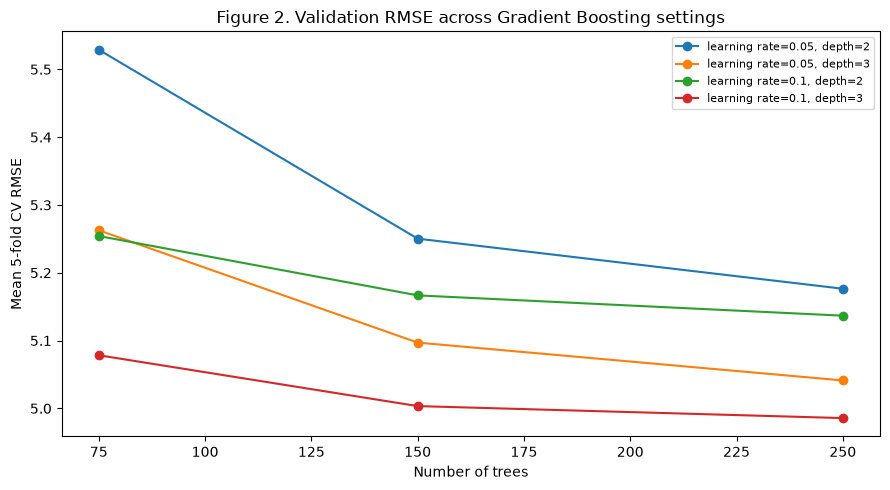

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for (lr, depth), group in results.groupby(['param_model__learning_rate', 'param_model__max_depth']):
    group = group.sort_values('param_model__n_estimators')
    ax.plot(group['param_model__n_estimators'].astype(int), group['CV RMSE'],
            marker='o', label=f'learning rate={lr}, depth={depth}')
ax.set(title='Figure 2. Validation RMSE across Gradient Boosting settings',
       xlabel='Number of trees', ylabel='Mean 5-fold CV RMSE')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Here we compare training and validation errors for the candidate settings. A large gap between them is a warning sign, even if training RMSE looks very good. 


Figure 2 shows that increasing the number of trees generally reduces the cross-validation RMSE for all four combinations of learning rate and tree depth.
The model with a **learning rate of 0.1 and a maximum depth of 3** consistently had the lowest error. Its RMSE decreased from **5.078** with 75 trees to **4.986** with 250 trees.
The model with a learning rate of 0.05 and depth of 2 performed the worst throughout. This suggests that a higher learning rate and deeper trees helped the model capture more of the patterns in our dataset.
However, the improvement between 150 and 250 trees was quite small for the best model, suggesting that adding more trees was starting to give smaller benefits.

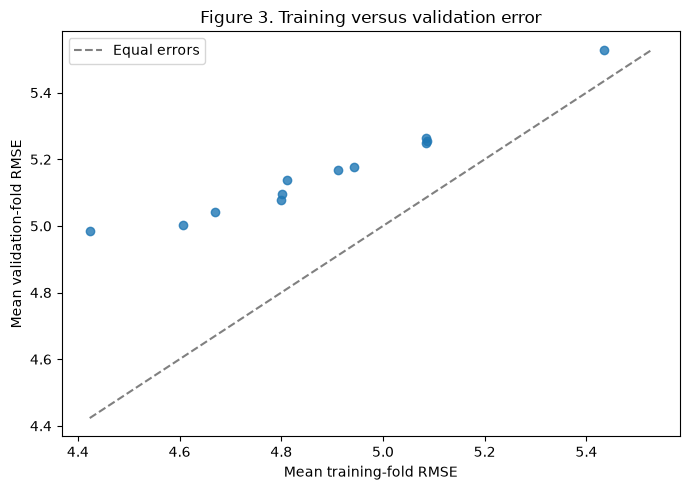

Best model training RMSE: 4.423
Best model CV RMSE: 4.986


In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(results['Train RMSE'], results['CV RMSE'], alpha=0.8)
lo = min(results['Train RMSE'].min(), results['CV RMSE'].min())
hi = max(results['Train RMSE'].max(), results['CV RMSE'].max())
ax.plot([lo, hi], [lo, hi], '--', color='gray', label='Equal errors')
ax.set(title='Figure 3. Training versus validation error',
       xlabel='Mean training-fold RMSE', ylabel='Mean validation-fold RMSE')
ax.legend(); plt.tight_layout(); plt.show()
print('Best model training RMSE:',
      round(-results.loc[search.best_index_, 'mean_train_score'], 3))
print('Best model CV RMSE:', round(-search.best_score_, 3))



Figure 3 shows that all the models have higher validation RMSE than training RMSE, as every point is above the dashed line. This means the models perform better on the data they were trained on than on unseen validation data.
For our best model, the training RMSE was **4.423**, compared with a validation RMSE of **4.986**, giving a difference of **0.563**.
This suggests that there is some overfitting, but the difference is not extremely large. The best model still achieved the lowest validation error, so we selected it for our final predictions.
Overall, the graph shows why we should not choose a model based only on its training accuracy, as a lower training error does not always mean better performance on unseen data.

## Experiment: does PCA help Gradient Boosting?
Our groupmate explored Principal Component Analysis (PCA) for Linear Regression, so we also test it as an optional step for Gradient Boosting.

PCA combines the original predictors into a smaller set of components. It may reduce redundant information, but it could also remove information that decision trees find useful. We don't assume PCA will improve the model, we test it. 
For a fair comparison, we use the same predictors, five cross-validation folds and Gradient Boosting settings for both versions. We standardise the encoded variables before PCA because PCA is sensitive to scale. Importantly, scaling and PCA are fitted inside each training fold using a pipeline, so information from the validation fold cannot leak into preprocessing.

We compare mean validation RMSE, then discuss whether any change is large enough to matter. The PCA version is an exploratory experiment. 

In [9]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Use the settings selected earlier, changing only whether PCA is included.
best_gb_settings = {
    key.replace('model__', ''): value
    for key, value in search.best_params_.items()
}

without_pca = make_model(**best_gb_settings)

# PCA needs a dense numeric matrix. OneHotEncoder is compatible with this
# because the ColumnTransformer converts the relatively small output to dense.
with_pca = Pipeline([
    ('preprocess', preprocessor),
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', GradientBoostingRegressor(
        random_state=RANDOM_STATE, subsample=1.0, **best_gb_settings
    ))
])

no_pca_scores, _ = evaluate_cv(without_pca, X_train, y_train)
pca_scores, _ = evaluate_cv(with_pca, X_train, y_train)

pca_comparison = pd.DataFrame({
    'Fold': np.arange(1, 6),
    'Without PCA RMSE': no_pca_scores,
    'With PCA RMSE': pca_scores,
})
display(pca_comparison.round(3))

print(f"Without PCA — mean CV RMSE: {no_pca_scores.mean():.3f}")
print(f"With PCA    — mean CV RMSE: {pca_scores.mean():.3f}")
print(f"Change (PCA minus no PCA): {pca_scores.mean() - no_pca_scores.mean():+.3f}")
print("Lower RMSE is better.")

# Inspect how many components PCA keeps when fitted to the full training set.
# This is descriptive only; the CV results above refit PCA within each fold.
with_pca.fit(X_train, y_train)
print("Components retained (95% explained variance):",
      with_pca.named_steps['pca'].n_components_)
print("Total encoded predictors:",
      with_pca.named_steps['pca'].n_features_in_)


,Fold,Without PCA RMSE,With PCA RMSE
0,1,5.016,5.553
1,2,5.037,5.565
2,3,4.867,5.298
3,4,5.070,5.439
4,5,4.938,5.276


Without PCA — mean CV RMSE: 4.986
With PCA    — mean CV RMSE: 5.426
Change (PCA minus no PCA): +0.440
Lower RMSE is better.
Components retained (95% explained variance): 19
Total encoded predictors: 25





Applying PCA made our Gradient Boosting model less accurate. Without PCA, the mean cross-validation RMSE was **4.986**, compared with **5.426** with PCA. This is an increase of **0.440**, or approximately **8.8%**.
PCA reduced the 25 encoded predictors to 19 components while retaining 95% of the variance. However, this did not improve prediction accuracy, suggesting that the original predictors were more useful for our model.
We therefore kept Gradient Boosting without PCA, as it gave better results and was easier to interpret. We did not separately retune the PCA model, so this conclusion applies to the settings we tested.




## Can we use AIC?
AIC balances model fit against complexity. For Linear Regression, counting parameters is fairly straightforward. For Gradient Boosting, it isn't: a fitted tree's leaves aren't the same as independent regression coefficients, and the trees are chosen based on earlier errors.

To explore the idea, we calculate an AIC-like score, using the total number of fitted terminal leaves plus one variance parameter as a rough measure of complexity. This is not formal AIC. We must not compare it directly with the Linear Regression AIC, and even comparing boosted models this way is only exploratory. Our group's actual ranking should use CV RMSE.

In [10]:
def exploratory_aic_like(fitted_pipeline, X, y):
    predictions = fitted_pipeline.predict(X)
    rss = np.sum((np.asarray(y) - predictions) ** 2)
    gb = fitted_pipeline.named_steps['model']
    leaves = sum(tree.get_n_leaves() for tree in gb.estimators_.ravel())
    k_proxy = leaves + 1  # +1 is a rough variance parameter count
    return len(y) * np.log(max(rss / len(y), 1e-12)) + 2 * k_proxy, leaves

rows = []
for label, estimator in [('Baseline', baseline), ('CV-selected', search.best_estimator_)]:
    estimator.fit(X_train, y_train)
    score, leaves = exploratory_aic_like(estimator, X_train, y_train)
    rows.append({'Model': label, 'Fitted leaves': leaves,
                 'Exploratory AIC-like (NOT formal AIC)': score})
aic_table = pd.DataFrame(rows)
display(aic_table.round(2))
print('Do not compare these values directly with linear-regression AIC.')

,Model,Fitted leaves,Exploratory AIC-like (NOT formal AIC)
0,Baseline,790,26112.24
1,CV-selected,1944,27556.11


Do not compare these values directly with linear-regression AIC.


### AIC-like Score: Results

The table shows that the baseline model had **790 fitted leaves** and an AIC-like score of **26,112.24**, while the tuned model had **1,944 leaves** and a higher score of **27,556.11**.
This suggests that the baseline model is preferred by our AIC-like measure because it is less complex. However, our earlier cross-validation results showed that the tuned model achieved better prediction accuracy.
Since this is only an approximate AIC-like score, we used cross-validation RMSE to select the best settings within Gradient Boosting. We can then use the model's test performance to help compare Gradient Boosting with Linear Regression and Random Forest in our group's final analysis.

## Does our choice of cross-validation matter?
One issue with our dataset is that the same school can appear in several years. We check how often school IDs occur in both the original train and test splits. That is not automatically wrong, but it changes what the test tells us: we may be predicting another year for a school the model has effectively already seen.

To see whether this matters, we also use [2]GroupKFold. This keeps all rows for a school in the same fold, so validation schools are genuinely unseen during training. This is a tougher test than ordinary random CV.

In [11]:
overlap = set(train_data.school_urn) & set(test_data.school_urn)
print('Schools appearing in both original splits:', len(overlap))
print('Repeated school IDs in training:', train_data.school_urn.duplicated().sum())
group_cv = GroupKFold(n_splits=5)
group_rmse, group_train_rmse = evaluate_cv(
    make_model(**{
        'n_estimators': search.best_params_['model__n_estimators'],
        'learning_rate': search.best_params_['model__learning_rate'],
        'max_depth': search.best_params_['model__max_depth']
    }), X_train, y_train, splitter=group_cv, groups=train_data.school_urn)
print('Ordinary tuned CV RMSE:', round(-search.best_score_, 3))
print('School-grouped CV RMSE:', round(group_rmse.mean(), 3))
print('School-grouped fold scores:', np.round(group_rmse, 3))

Schools appearing in both original splits: 1547
Repeated school IDs in training: 4524
Ordinary tuned CV RMSE: 4.986
School-grouped CV RMSE: 5.269
School-grouped fold scores: [5.258 5.072 5.695 5.244 5.075]




We found that **1,547 schools appear in both the training and test datasets**, although they are recorded in different years.

Our ordinary 5-fold cross-validation gave an RMSE of **4.986**, while school-grouped cross-validation gave a higher RMSE of **5.269**. This is an increase of **0.283**, or around **5.7%**.

This suggests that our model performs slightly worse when predicting schools it has not seen before. The ordinary cross-validation results may therefore be a little optimistic because the same schools can appear in different folds.

We can go one step further and hold out whole local authorities. Schools in the same area may share factors that are missing from our data. If performance gets worse when whole areas are left out, the ordinary CV result may be too optimistic for predicting schools in new areas.

,Validation method,Mean RMSE,Fold SD
0,Ordinary random 5-fold,4.986,0.082
1,School-grouped 5-fold,5.269,0.254
2,Local-authority-grouped 5-fold,5.346,0.383


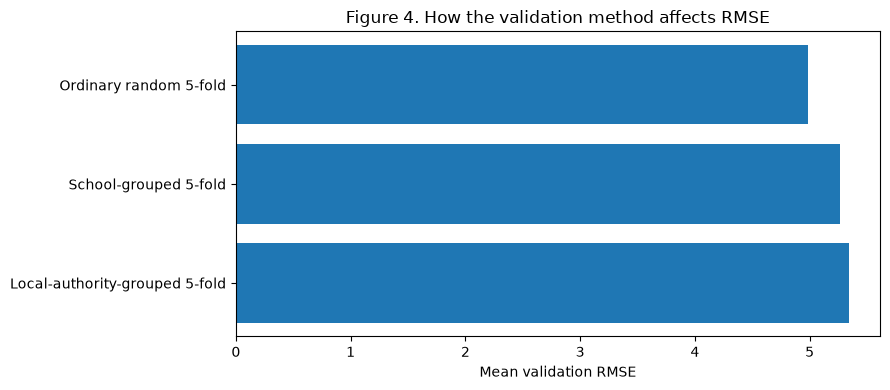

In [12]:
la_cv = GroupKFold(n_splits=5)
la_rmse, _ = evaluate_cv(search.best_estimator_, X_train, y_train,
                        splitter=la_cv, groups=train_data.new_la_code)
cv_comparison = pd.DataFrame({
    'Validation method': ['Ordinary random 5-fold', 'School-grouped 5-fold',
                          'Local-authority-grouped 5-fold'],
    'Mean RMSE': [-search.best_score_, group_rmse.mean(), la_rmse.mean()],
    'Fold SD': [results.loc[search.best_index_, 'std_test_score'] * np.sqrt(5/4),
                group_rmse.std(ddof=1), la_rmse.std(ddof=1)]
})
display(cv_comparison.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cv_comparison['Validation method'], cv_comparison['Mean RMSE'])
ax.invert_yaxis(); ax.set(xlabel='Mean validation RMSE',
                         title='Figure 4. How the validation method affects RMSE')
plt.tight_layout(); plt.show()



Figure 4 shows that the choice of cross-validation method affects our model's performance.
The ordinary random 5-fold method had the lowest RMSE of **4.986**, followed by school-grouped cross-validation at **5.269**. Local-authority-grouped cross-validation had the highest RMSE of **5.346**.
This means our model makes larger errors when predicting completely new schools or schools in different local authorities. The results suggest that schools in the same area may share patterns that help the model make predictions.
The standard deviation also increased from **0.082** for ordinary cross-validation to **0.383** for local-authority-grouped cross-validation. This shows that performance varies more depending on which local authorities are held out.
Overall, the model still performs reasonably well, but its accuracy is less reliable when predicting schools and areas it has not seen during training.

## Which variables appear most useful?
We use permutation importance: we shuffle one variable at a time and see how much the model's prediction error increases. This is more interpretable than just counting how often a tree splits on something.

Here we use training data for a descriptive check, not as evidence of performance on new schools.

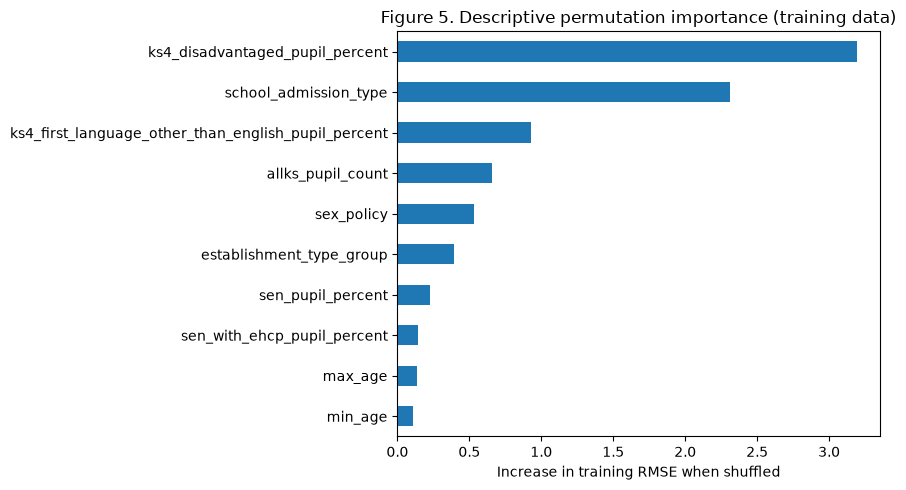

In [13]:
best_model = search.best_estimator_  # fitted on all training data by GridSearchCV
importance = permutation_importance(
    best_model, X_train, y_train, scoring='neg_root_mean_squared_error',
    n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(importance.importances_mean, index=features).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
imp.plot.barh(ax=ax)
ax.set(xlabel='Increase in training RMSE when shuffled',
       title='Figure 5. Descriptive permutation importance (training data)')
plt.tight_layout(); plt.show()



Figure 5 shows that **the percentage of disadvantaged pupils** is the most important variable in our Gradient Boosting model, followed by **school admission type**. Shuffling these variables increased the training RMSE by approximately **3.2** and **2.3**, respectively.
The percentage of pupils whose first language is not English was the third most important variable, but had a much smaller effect on the model's predictions.
In comparison, variables such as minimum and maximum school age and the percentage of pupils with an EHCP had very little importance.
Overall, this suggests that **pupil disadvantage and school admission type are the strongest predictors of Attainment 8** among the variables we selected. However, these results only show which variables the model relies on, not that they directly cause differences in attainment.

## Final evaluation on the held-out test data
Now that we've chosen our settings, we finally use the test data. We only use it once for the final model assessment. We report test RMSE alongside MAE and \(R^2\), but our group's main comparison metric is RMSE.

Test RMSE: 4.929
Test MAE:  3.821
Test R²:   0.694


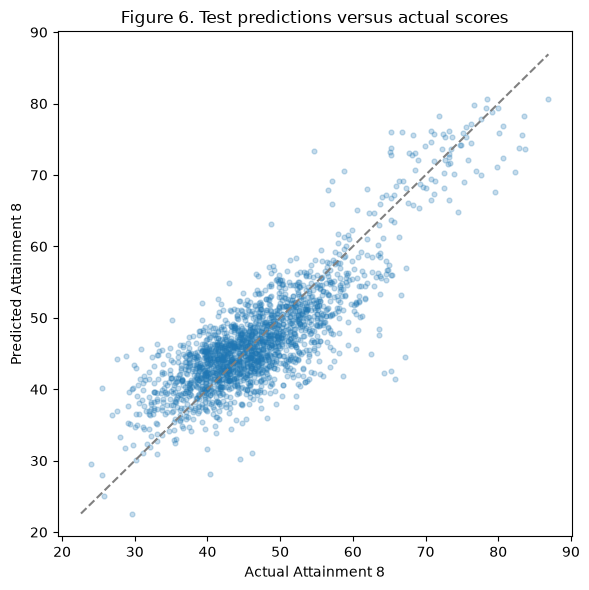

In [14]:
test_predictions = best_model.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_mae = mean_absolute_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)
print(f'Test RMSE: {test_rmse:.3f}')
print(f'Test MAE:  {test_mae:.3f}')
print(f'Test R²:   {test_r2:.3f}')
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_predictions, alpha=0.25, s=12)
lims = [min(y_test.min(), test_predictions.min()),
        max(y_test.max(), test_predictions.max())]
ax.plot(lims, lims, '--', color='gray')
ax.set(xlabel='Actual Attainment 8', ylabel='Predicted Attainment 8',
       title='Figure 6. Test predictions versus actual scores')
plt.tight_layout(); plt.show()

### Final Model Evaluation

Our final Gradient Boosting model achieved a test RMSE of **4.929**, an MAE of **3.821**, and an R² of **0.694** on the held-out test dataset.

The R² value suggests that the model explains approximately 69.4% of the variation in school-level Attainment 8 scores. The MAE indicates that predictions were, on average, around 3.82 points away from the actual scores.

The test RMSE of 4.929 was also very close to the 5-fold cross-validation RMSE of 4.986. This suggests that the model generalises reasonably well to unseen observations, with no clear evidence of substantial overfitting.

Looking at Figure 6, most predictions follow the diagonal line, showing that the model captures the overall relationship between predicted and actual scores, but there is some variation around the line, particularly for schools with unusually high or low attainment, where predictions appear less accurate.

One limitation is that some schools appear in both the training and test datasets for different academic years. Therefore, these results do not necessarily show how well the model would perform on entirely new schools.

Overall, the model shows reasonable predictive performance, although there is still unexplained variation. This highlights the difficulty of predicting educational attainment using a limited set of school characteristics.


## Residual Analysis

We looked at the residuals to see where our Gradient Boosting model was making errors. We first look at the training residuals to see how well the model fits the data it was trained on. We then look at the test residuals to see how well it performs on unseen data.


In [15]:

# Predictions from our fitted Gradient Boosting model
train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

# Residuals = actual minus predicted
train_residuals = np.asarray(y_train) - train_predictions
test_residuals = np.asarray(y_test) - test_predictions

print("Training RMSE:", round(np.sqrt(np.mean(train_residuals**2)), 3))
print("Test RMSE:", round(np.sqrt(np.mean(test_residuals**2)), 3))


Training RMSE: 4.495
Test RMSE: 4.929


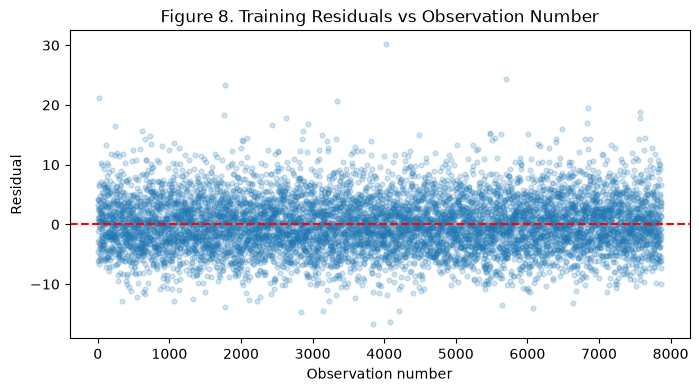

In [16]:

plt.figure(figsize=(8, 4))

plt.scatter(
    range(len(train_residuals)),
    train_residuals,
    alpha=0.2,
    s=12
)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel('Observation number')
plt.ylabel('Residual')
plt.title('Figure 8. Training Residuals vs Observation Number')

plt.show()


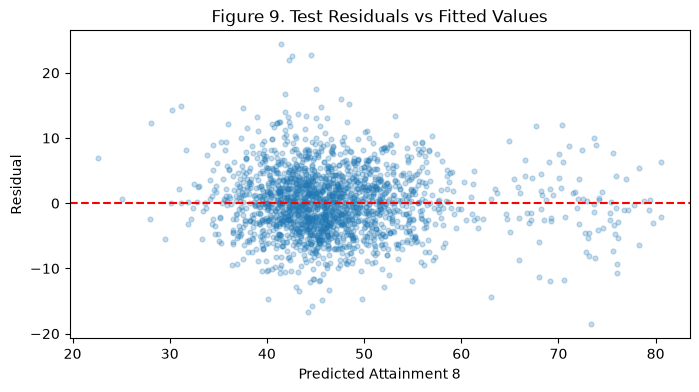

In [17]:

plt.figure(figsize=(8, 4))

plt.scatter(
    test_predictions,
    test_residuals,
    alpha=0.25,
    s=12
)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel('Predicted Attainment 8')
plt.ylabel('Residual')
plt.title('Figure 9. Test Residuals vs Fitted Values')

plt.show()


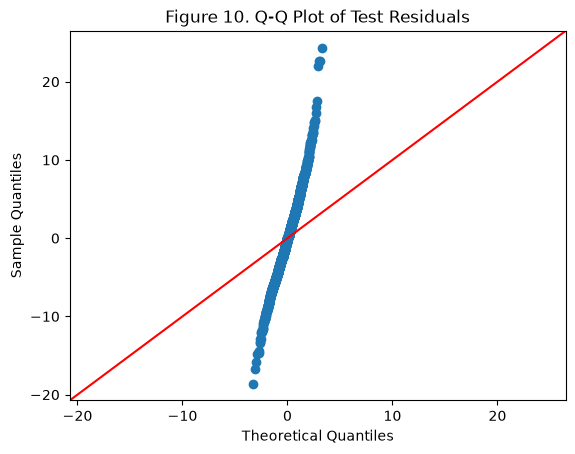

In [18]:

import statsmodels.api as sm

sm.qqplot(test_residuals, line='45')

plt.title('Figure 10. Q-Q Plot of Test Residuals')
plt.show()




Figure 8 shows that the training residuals are mostly spread around zero, with no obvious pattern across the observations. This suggests that the model is not consistently overpredicting or underpredicting throughout the training dataset. However, there are some larger errors, including a few positive residuals above 20. The training RMSE was **4.495**, compared with **4.929** on the test data. This small increase suggests that the model generalises reasonably well, although it performs slightly better on the data it was trained on.

Figure 9 shows that most predictions are concentrated around Attainment 8 scores of **40–55**, with residuals generally close to zero. However, some errors are much larger, reaching above +20 and below −15. There also appear to be more negative residuals among some of the highest predicted scores, suggesting that the model sometimes overpredicts attainment for these schools. Overall, the model performs reasonably well for many schools, but its predictions are not equally accurate across the full range of scores.

Figure 10 shows that the residuals do not closely follow the red reference line, particularly at the upper and lower ends. This suggests that the errors are not normally distributed and that there are more extreme residuals than we would expect from a normal distribution. Although Gradient Boosting does not require normally distributed residuals, this shows that the model still makes some unusually large prediction errors.

Our test RMSE of **4.929** suggests that the model makes reasonably accurate predictions overall. However, the residual plots show that some schools have much larger errors than others. This suggests that the school characteristics we selected do not fully explain the differences in Attainment 8 scores.

## Overall Conclusion and Limitations

Our Gradient Boosting model achieved a test RMSE of **4.929**, an MAE of **3.821**, and an R² of **0.694**, showing that it can predict school-level Attainment 8 reasonably well using the selected school characteristics.
Tuning the model helped improve its predictions, while applying PCA made performance worse. We also found that the model performed less well when cross-validation was grouped by school or local authority, suggesting that ordinary random cross-validation may give slightly optimistic results.
The residual analysis showed that some schools still had much larger prediction errors than others, particularly at more extreme attainment levels.
Overall, Gradient Boosting was a useful approach, but its accuracy depends partly on which schools are being predicted. The next step is to compare its performance with our group's Linear Regression and Random Forest models using consistent evaluation criteria.

## References:


[1] scikit-learn developers (n.d.) *Gradient Boosting*. scikit-learn User Guide. Available at: https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting (Accessed: 1 November 2026).

[2] Scholar (n.d.) Gradient Boosting Tree. Scholar Documentation. Available at: https://scholar.hexdocs.pm/cv_gradient_boosting_tree.html (Accessed: 2 November 2026).

[3] GeeksforGeeks (n.d.) *Gradient Boosting in Machine Learning*. Available at: https://www.geeksforgeeks.org/machine-learning/ml-gradient-boosting/ (Accessed: 1 November 2026).